In [9]:
import numpy as np
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
import copy

def detector_builder(mseq, syndromelength=6, nphysicalqubits=7, nrounds=1, mode='binary'):
    if len(mseq) != syndromelength * (nrounds + 1) + nphysicalqubits:
        raise ValueError(f"Measurement sequence length must be equal to syndromelength * (nrounds + 1) + nphysicalqubits")
    syndromes, finalmeasurement = mseq[:-nphysicalqubits], mseq[-nphysicalqubits:]
    if mode == 'string':
        det = []
        for i in range(nrounds):
            det.append(''.join([str(0 if x == y else 1) for x, y in zip(syndromes[i*syndromelength:(i+1)*syndromelength], syndromes[(i+1)*syndromelength:(i+2)*syndromelength])]))
    elif mode == 'binary':
        det = np.zeros(nrounds * syndromelength, dtype=np.bool_)
        for i in range(nrounds):
            det[i*syndromelength:(i+1)*syndromelength] = np.array([0 if x == y else 1 for x, y in zip(syndromes[i*syndromelength:(i+1)*syndromelength], syndromes[(i+1)*syndromelength:(i+2)*syndromelength])])
    else:
        raise ValueError(f"Invalid mode: {mode}")
    return det, finalmeasurement

def check_detector_fired(det):
    for detector in det:
        if '1' in detector:
            return True
    return False

def measure_readout(readout, logical_operator):
    parity = 0
    for i in range(len(readout)):
        if readout[i] == '1' and logical_operator[i]:
            parity += 1
    return parity % 2

def get_text(name):
    txt = os.path.join(path, f'{name}.txt')
    with open(txt, 'r') as f:
        return f.read()

def get_data(name, n, er):
    syndromelength = 6  # 3 Z + 3 X Steane ancillas
    width = (nrounds[n] + 2) * syndromelength + 7
    # 8 coupling windows per noise round (4 Z + 4 X) matching c713 schedules
    idlequbitfailure = (1 - (1 - 2 * ers[er])**(nrounds[n] * 8)) / 2
    binpath = os.path.join(path, f'{name}_n{n}_er{er}.bin')
    data = np.fromfile(binpath, dtype=[('bits', np.uint64), ('count', np.uint32)])
    bitstrings = [np.binary_repr(row['bits'], width=width) for row in data]
    counts = [row['count'] for row in data]
    return bitstrings, counts, syndromelength, idlequbitfailure

# Steane [[7,1,3]] X-stabilizer codespace (even parity on X0:0123, X1:0145, X2:0246)
xreadoutspace = [
    '0000000', '1111000', '0110100', '1001100',
    '1010010', '0101010', '1100110', '0011110',
    '1100001', '0011001', '1010101', '0101101',
    '0110011', '1001011', '0000111', '1111111',
]

def get_schedule(info):
    """Parse the two 3x7 schedule arrays printed at the top of a sim713 .txt file."""
    first_begin = info.index('[[')
    first_end = info.index(']]', first_begin) + 2
    second_begin = info.index('[[', first_end)
    second_end = info.index(']]', second_begin) + 2
    zschedule = np.zeros((3, 7), dtype=int)
    index = 0
    for char in info[first_begin+1:first_end-1]:
        if char == ' ' or char == '\n' or char == '[' or char == ']':
            continue
        zschedule[index // 7, index % 7] = int(char)
        index += 1
    index = 0
    xschedule = np.zeros((3, 7), dtype=int)
    for char in info[second_begin+1:second_end-1]:
        if char == ' ' or char == '\n' or char == '[' or char == ']':
            continue
        xschedule[index // 7, index % 7] = int(char)
        index += 1
    return zschedule, xschedule

def has_hook_error(z, x):
    hook_error_locations = []
    for row in z:
        for twindow in range(1, int(np.max(z))):
            mask = row > twindow
            xsyndrome = np.zeros((x.shape[0], x.shape[1]), dtype=bool)
            for j in range(x.shape[0]):
                masked = (x[j] > 0) & mask
                xsyndrome[j] = masked
            fallthrough = True
            for j in range(xsyndrome.shape[0]):
                if np.sum(xsyndrome[j]) == 1 or np.sum(xsyndrome[j]) == 3:
                    fallthrough = False
                    break
            if fallthrough:
                hook_error_locations.append((row.copy(), twindow))
    return True if len(hook_error_locations) > 0 else False

path = 'sim713'
imgdir = 'imgs713'
os.makedirs(imgdir, exist_ok=True)
nrounds = [1, 2, 4]
ers = [0.0001, 0.001, 0.01]
# Steane logical X = X^{\otimes 7}
default_logop = np.array([1, 1, 1, 1, 1, 1, 1])

In [10]:
def sim_analysis(bitstrings, counts, syndromelength, idlequbitfailure, logop):
    totalshots = 0
    # s = survived detector postselection, c = correct readout, r = in readout space
    s, c, r, candr, sandr, sandc, sandrandc = 0, 0, 0, 0, 0, 0, 0
    for i in range(len(bitstrings)):
        bitstring = bitstrings[i]
        count = counts[i]
        totalshots += count
        det, finalmeasurement = detector_builder(bitstring, syndromelength, 7, nrounds[n] + 1, mode='string')
        inreadoutspace = finalmeasurement in xreadoutspace
        correctreadout = measure_readout(finalmeasurement, logop) == 0
        survives = not check_detector_fired(det)

        if inreadoutspace:
            r += count
        if correctreadout:
            c += count
        if inreadoutspace and correctreadout:
            candr += count
        if survives:
            s += count
            if inreadoutspace:
                sandr += count
            if correctreadout:
                sandc += count
            if inreadoutspace and correctreadout:
                sandrandc += count
    return totalshots, s, r, c, candr, sandr, sandc, sandrandc

bitstrings, counts, syndromelength, idlequbitfailure = get_data(name, n, er)
logop = default_logop
totalshots, s, r, c, candr, sandr, sandc, sandrandc = sim_analysis(bitstrings, counts, syndromelength, idlequbitfailure, logop)
print(f'Total shots: {totalshots}')
print(f'Survived: {s}')
print(f'In readout space: {r}')
print(f'Correct readout: {c}')
print(f'Correct and in readout space: {candr}')
print(f'Survived and in readout space: {sandr}')
print(f'Survived and correct readout: {sandc}')
print(f'Survived and in readout space and correct readout: {sandrandc}')
print('----------')
print(f'Raw LER: {1 - c / totalshots}, ({totalshots - c} / {totalshots})')
print(f'LER with postsel: {1 - sandc / s}, ({s - sandc} / {s})')
print('----------')
print(f'LER of idle qubit for same clock: {idlequbitfailure}')

Total shots: 1000000
Survived: 17781
In readout space: 187433
Correct readout: 507553
Correct and in readout space: 152681
Survived and in readout space: 17781
Survived and correct readout: 17717
Survived and in readout space and correct readout: 17717
----------
Raw LER: 0.49244699999999997, (492447 / 1000000)
LER with postsel: 0.0035993476182442086, (64 / 17781)
----------
LER of idle qubit for same clock: 0.23805842983255382


In [5]:
# Optional: inspect bitstrings and counts in descending order for the current (name, n, er)
name = 'default'
n = 2
er = 1
width = (nrounds[n] + 2) * syndromelength + 7
binpath = os.path.join(path, f'{name}_n{n}_er{er}.bin')
data = np.fromfile(binpath, dtype=[('bits', np.uint64), ('count', np.uint32)])
data_sorted = sorted(data, key=lambda row: row['count'], reverse=True)
bitstrings_sorted = [np.binary_repr(row['bits'], width=width) for row in data_sorted]
counts_sorted = [row['count'] for row in data_sorted]
for i in range(min(20, len(bitstrings_sorted))):
    print(bitstrings_sorted[i], counts_sorted[i], *detector_builder(bitstrings_sorted[i], syndromelength, 7, nrounds[n] + 1, mode='string'))

0100000100000100000100000100000100001001011 10730 ['000000', '000000', '000000', '000000', '000000'] 1001011
0000000000000000000000000000000000000000000 10687 ['000000', '000000', '000000', '000000', '000000'] 0000000
0000000000000000000000000000000000001001011 10667 ['000000', '000000', '000000', '000000', '000000'] 1001011
0010000010000010000010000010000010001010101 10662 ['000000', '000000', '000000', '000000', '000000'] 1010101
0100000100000100000100000100000100000101101 10634 ['000000', '000000', '000000', '000000', '000000'] 0101101
0000000000000000000000000000000000000101101 10633 ['000000', '000000', '000000', '000000', '000000'] 0101101
1010001010001010001010001010001010001010101 10624 ['000000', '000000', '000000', '000000', '000000'] 1010101
0110000110000110000110000110000110001010101 10594 ['000000', '000000', '000000', '000000', '000000'] 1010101
0110000110000110000110000110000110001001011 10580 ['000000', '000000', '000000', '000000', '000000'] 1001011
1000001000001000001

In [12]:
name = 'default'
# name = 'rand0'
info = get_text(name)
print(info)
cLERs = np.zeros((len(nrounds), len(ers)))
numers = np.zeros((len(nrounds), len(ers)))
denoms = np.zeros((len(nrounds), len(ers)))
idles = np.zeros((len(nrounds), len(ers)))
logop = default_logop
print('logop:', logop)
for n in range(len(nrounds)):
    for er in range(len(ers)):
        bitstrings, counts, syndromelength, idlequbitfailure = get_data(name, n, er)
        totalshots, s, r, c, candr, sandr, sandc, sandrandc = sim_analysis(bitstrings, counts, syndromelength, idlequbitfailure, logop)
        cLERs[n, er] = 1 - sandc / s
        numers[n, er] = s - sandc
        denoms[n, er] = s
        idles[n, er] = idlequbitfailure

[[1 2 3 4 0 0 0]
 [2 1 0 0 3 4 0]
 [3 0 1 0 2 0 4]]
[[1 2 3 4 0 0 0]
 [2 1 0 0 3 4 0]
 [3 0 1 0 2 0 4]]
      /-----------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /------------------------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /---------------------------------------------------------------------------\ /------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------\
 q0: -R-H-@-

/tmp/ipykernel_3665469/1939972656.py:2: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.log10(cLERs), aspect='auto', origin='lower', cmap='RdBu_r', vmin=-4, vmax=np.log10(0.5), alpha=0.8)


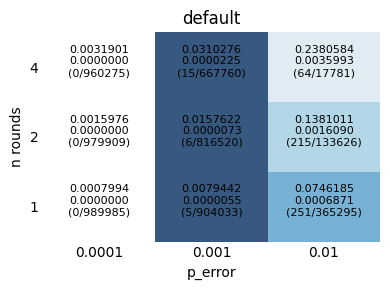

In [13]:
fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(np.log10(cLERs), aspect='auto', origin='lower', cmap='RdBu_r', vmin=-4, vmax=np.log10(0.5), alpha=0.8)
for n in range(len(nrounds)):
    for er in range(len(ers)):
        cLER_val = cLERs[n, er]
        text = f"{idles[n, er]:.7f}\n{cLER_val:.7f}\n({numers[n, er]:.0f}/{denoms[n, er]:.0f})\n"
        ax.text(er, n, text, ha='center', va='center', color='black', fontsize=8)

ax.set_xlabel('p_error')
ax.set_ylabel('n rounds')
ax.set_title(f'{name}')
ax.set_xticks(np.arange(len(ers)))
ax.set_xticklabels([str(e) for e in ers])
ax.set_yticks(np.arange(len(nrounds)))
ax.set_yticklabels([str(nr) for nr in nrounds])
ax.tick_params(axis='both', which='both', length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# Baseline only: default schedule + randomized coupling schedules from c713.py
allnames = ['default']
# Discover whatever rand*.txt files are present under sim713
for fname in sorted(os.listdir(path)):
    if fname.startswith('rand') and fname.endswith('.txt') and '_n' not in fname:
        allnames.append(fname[:-4])
print(allnames)
print(len(allnames))

In [ ]:
for name in tqdm(allnames):
    info = get_text(name)
    cLERs = np.zeros((len(nrounds), len(ers)))
    numers = np.zeros((len(nrounds), len(ers)))
    denoms = np.zeros((len(nrounds), len(ers)))
    idles = np.zeros((len(nrounds), len(ers)))
    logop = default_logop
    for n in range(len(nrounds)):
        for er in range(len(ers)):
            bitstrings, counts, syndromelength, idlequbitfailure = get_data(name, n, er)
            totalshots, s, r, c, candr, sandr, sandc, sandrandc = sim_analysis(bitstrings, counts, syndromelength, idlequbitfailure, logop)
            cLERs[n, er] = 1 - sandc / s
            numers[n, er] = s - sandc
            denoms[n, er] = s
            idles[n, er] = idlequbitfailure
    fig, ax = plt.subplots(figsize=(4, 3))
    im = ax.imshow(np.log10(cLERs), aspect='auto', origin='lower', cmap='RdBu_r', vmin=-4, vmax=np.log10(0.5), alpha=0.8)
    for n in range(len(nrounds)):
        for er in range(len(ers)):
            cLER_val = cLERs[n, er]
            text = f"{idles[n, er]:.7f}\n{cLER_val:.7f}\n({numers[n, er]:.0f}/{denoms[n, er]:.0f})\n"
            ax.text(er, n, text, ha='center', va='center', color='black', fontsize=8)
    ax.set_xlabel('p_error')
    ax.set_ylabel('n rounds')
    ax.set_title(f'{name}')
    ax.set_xticks(np.arange(len(ers)))
    ax.set_xticklabels([str(e) for e in ers])
    ax.set_yticks(np.arange(len(nrounds)))
    ax.set_yticklabels([str(nr) for nr in nrounds])
    ax.tick_params(axis='both', which='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.savefig(f'{imgdir}/{name}.png')
    stack = np.stack([cLERs, numers, denoms, idles], axis=0)
    stack.tofile(f'{imgdir}/{name}_stack.bin')
    plt.close()

In [ ]:
vals = []
for name in allnames:
    stack = np.fromfile(f'{imgdir}/{name}_stack.bin', dtype=np.float64).reshape(4, len(nrounds), len(ers))
    # Compare at nrounds=4 (index 2), er=0.001 (index 1) — same slice as 832 notebook
    rel = stack[0, 2, 1]
    vals.append(rel)
vals = np.array(vals)
names = copy.deepcopy(allnames)

In [ ]:
sorted_indices = np.argsort(vals)[::-1]
vals_sorted = vals[sorted_indices]
names_sorted = [names[i] for i in sorted_indices]
for i in range(len(vals_sorted)):
    print(f'{names_sorted[i]} {vals_sorted[i]:.7f}')

In [ ]:
lookat = 0

In [8]:
name = names_sorted[lookat] if 'names_sorted' in dir() else allnames[lookat]
print(name)
lookat += 1
stack = np.fromfile(f'{imgdir}/{name}_stack.bin', dtype=np.float64).reshape(4, len(nrounds), len(ers))
rel, reln, reld = stack[0, 2, 2], stack[1, 2, 2], stack[2, 2, 2]
print(rel, f'{int(reln)}/{int(reld)}')
info = get_text(name)
zschedule, xschedule = get_schedule(info)
print('zschedule:\n', zschedule)
print('xschedule:\n', xschedule)
print('Expect hook errors:', has_hook_error(zschedule, xschedule))
print(info[:800])

NameError: name 'allnames' is not defined